# V2R universe —> dimensionality reduction
ESM2-650M mean-pooled embeddings of **VFT + core** domains (2423 intact V2Rs, 12 species).
**Clustering uses sequence only** (species / chromosome / habitat are post-hoc colour — CLAUDE.md §2.1).
UMAP projection + HDBSCAN clusters. Post-hoc panels use the cmcrameri **roma** gradient.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from cmcrameri import cm as cmc
from sklearn.preprocessing import StandardScaler
import hdbscan
import umap
import warnings
import seaborn as sns
import matplotlib.cm as cm

from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph
import igraph as ig
import leidenalg

import sys, types
from pathlib import Path

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.neighbors import kneighbors_graph
import igraph as ig
import leidenalg


/hpcfs/users/a1864358/miniconda/envs/general/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

warnings.filterwarnings("ignore")  # mute warnings

H = "/hpcfs/users/a1864358/sanders_lab/phylogenomics/v2r_tree/workspace/data/familyC/domain_hmm"  # ESM2 per-domain embeddings (.npy) + gene-name list
COV = "/hpcfs/users/a1864358/sanders_lab/phylogenomics/v2r_tree/workspace/data/familyC/covariates.tsv"  # per-gene metadata for post-hoc colouring
OUT = "/hpcfs/users/a1864358/sanders_lab/phylogenomics/v2r_tree/results/analysis"

def save_panels(fig, panels, stem):
    """Save each scatter axis on its own, with the title cleared. The legend sits on another axis, so it is not included."""
    for ax, name in panels:
        title = ax.get_title()
        ax.set_title("")
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        box = ax.get_tightbbox(renderer).transformed(fig.dpi_scale_trans.inverted()).padded(0.03)
        fig.savefig(f"{stem}_{name}.png", dpi=150, bbox_inches=box)
        ax.set_title(title)



#### Load ESM2(VFT+core) embeddings → standardise

In [3]:
# Load mean-pooled ESM2-650M embeddings for the two domains of each V2R:
#   vft  = ligand-binding "Venus Flytrap" ectodomain, core = 7tm = 7-transmembrane domain
vft = np.load(f"{H}/vft.esm2.npy")
core = np.load(f"{H}/core.esm2.npy")

names = open(f"{H}/vft.esm2.names.txt").read().split()   # gene ids, row-aligned with the arrays


# Concatenate both domain vectors per gene, then flag rows that are fully finite
# (drop any gene with NaN/inf in either domain so downstream scaling/UMAP stay valid).
X = np.hstack([vft, core])
ok = np.isfinite(X).all(1)
X, names = X[ok], [n for n, f in zip(names, ok) if f]   # keep good rows and their names in sync

Xs = StandardScaler().fit_transform(X)   # z-score each feature so no dimension dominates UMAP distances
print("universe", X.shape)               # (n_genes, vft_dim + core_dim)

universe (2423, 2560)


#### UMAP (2D for the figure) + HDBSCAN clusters (sequence only)

In [4]:
# Two independent UMAPs of the same standardised features (random_state=42):
#   red2  -> 2D layout for the figure only (min_dist=0.1 spreads points for readability).
#   red15 -> 15D embedding for clustering only (min_dist=0.0 keeps points packed
#            so HDBSCAN sees denser structure than the flattened 2D view).
red2  = umap.UMAP(n_components=2,  n_neighbors=30, min_dist=0.1, random_state=42).fit_transform(Xs)
red15 = umap.UMAP(n_components=15, n_neighbors=30, min_dist=0.0, random_state=42).fit_transform(Xs)
# Density-based clustering on the 15D embedding; cluster count is not imposed.
# Label -1 is noise.
lab = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(red15)
nclust = len(set(lab)) - (1 if -1 in lab else 0)   # real clusters, excluding -1
print(f"HDBSCAN: {nclust} clusters, {(lab==-1).sum()} unclustered")

# Per-gene table: 2D coords (for plotting) and cluster id.
df = pd.DataFrame({"gene": names, "umap1": red2[:,0], "umap2": red2[:,1], "cluster": lab})
cov = pd.read_csv(COV, sep="\t")
# Metadata merge is post-hoc colour only (clustering above used sequence embeddings alone).
df = df.merge(cov[["gene","species","marine","chrom_hydrophis","arr100"]], on="gene", how="left")
df.to_csv(f"{OUT}/universe_umap.tsv", sep="\t", index=False)   # persist coords + labels + metadata

HDBSCAN: 58 clusters, 369 unclustered


### UMAP 
- preserves global data structure (better for large data sets)

HDBSCAN:

Species, chromosome and habitat were coloured post-hoc.

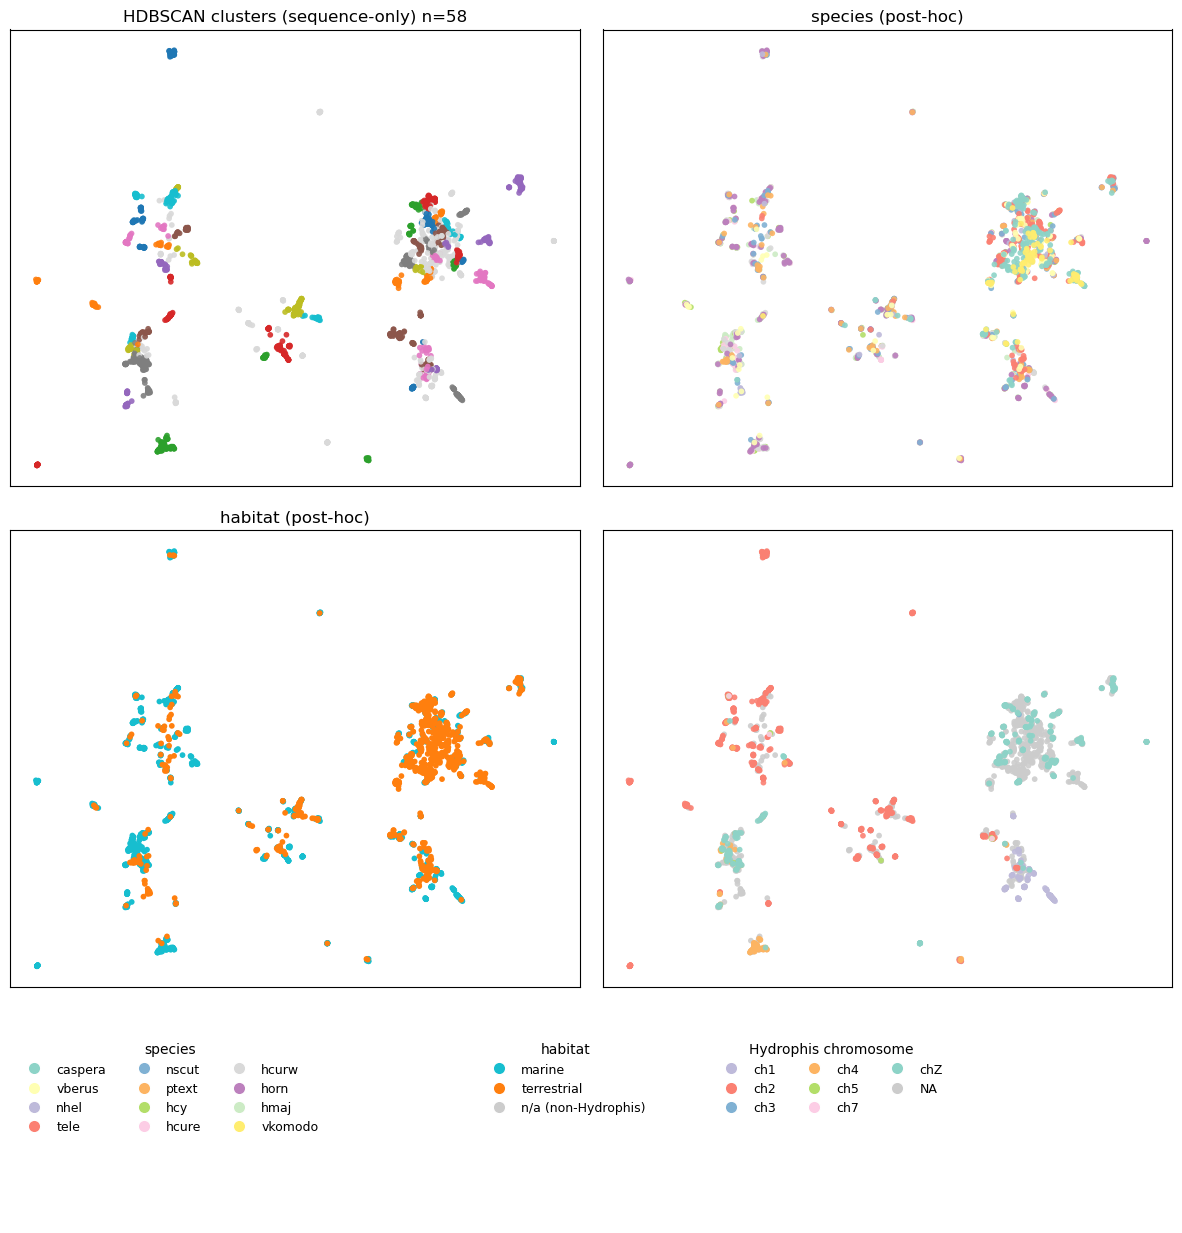

In [5]:
def roma(n): 
    return [cmc.roma(x) for x in np.linspace(0,1,max(n,1))]

SPP = ["caspera","vberus","nhel","tele","nscut","ptext","hcy","hcure","hcurw","horn","hmaj","vkomodo"]

# habitat
set2 = cm.get_cmap("tab10")
HAB_COL = {
    "marine": set2(9),
    "terrestrial": set2(1),
    "NA": "#cccccc"
}

# cluster ids
big = (list(plt.get_cmap("tab10").colors))
clcol = lambda k: "#d9d9d9" if k==-1 else big[int(k)%len(big)]

# chromosomes
chroms = sorted(c for c in df.chrom_hydrophis.fillna("NA").astype(str).unique() if c != "NA")
_set1 = plt.get_cmap("Set3").colors
_set1_shifted = _set1[2:]
chcol = {c: _set1_shifted[i % len(_set1_shifted)] for i, c in enumerate(chroms)}
chcol["NA"] = "#cccccc"
chcol["chZ"] = cm.get_cmap("Set3")(0)

# To plot "NA" points behind others, prepare a mask:
chs = df.chrom_hydrophis.fillna("NA").astype(str)
na_mask = (chs == "NA")
non_na_mask = ~na_mask


S, A = 17, 0.9   # scatter marker size and alpha, shared across all four panels

fig = plt.figure(figsize=(15,15.5))

gs = GridSpec(3,2, height_ratios=[1,1,0.42], hspace=0.12, wspace=0.04)   # row 3 = short legend strip

axTL, axTR = fig.add_subplot(gs[0,0]),fig.add_subplot(gs[0,1])
axBL, axBR = fig.add_subplot(gs[1,0]),fig.add_subplot(gs[1,1])

cap = fig.add_subplot(gs[2,:]); cap.axis("off")   # full-width caption axis, only hosts legends

for a in (axTL,axTR,axBL,axBR): a.set_xticks([]); a.set_yticks([])   # UMAP axes are unitless -> hide ticks

# Top-left: colour by HDBSCAN cluster (the actual sequence-only result).
axTL.scatter(df.umap1,df.umap2,c=[clcol(k) for k in df.cluster],s=S,alpha=A,lw=0)
axTL.set_title(f"HDBSCAN clusters (sequence-only) n={nclust}",fontsize=12)

# species
spcol = dict(zip(SPP, plt.get_cmap("Set3").colors[:len(SPP)]))
axTR.scatter(df.umap1, df.umap2, c=[spcol.get(s, "#cccccc") for s in df.species], s=S, alpha=A, lw=0)
axTR.set_title("species (post-hoc)", fontsize=12)

# habitat 
hab = df.marine.map({True:"marine", False:"terrestrial"}).fillna("NA")
axBL.scatter(df.umap1,df.umap2,c=[HAB_COL[h] for h in hab],s=S,alpha=1.0,lw=0)
axBL.set_title("habitat (post-hoc)",fontsize=12)

# chromosomes
axBR.scatter(df.umap1[na_mask], df.umap2[na_mask], c=[chcol["NA"]]*na_mask.sum(), s=S, alpha=A, lw=0, zorder=1)
for chrom in chroms:
    mask = (chs == chrom)
    axBR.scatter(df.umap1[mask], df.umap2[mask], c=[chcol[chrom]]*mask.sum(), s=S, alpha=A, lw=0, zorder=2)

# legend
dot = lambda col: Line2D([0],[0],marker="o",color="w",markerfacecolor=col,markersize=9)
ck = chroms + ["NA"]

l1 = cap.legend([dot(spcol[s]) for s in SPP], SPP, title="species", loc="upper left",
                bbox_to_anchor=(0.0,1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
l2 = cap.legend([dot(HAB_COL[k]) for k in ["marine","terrestrial","NA"]],
                ["marine","terrestrial","n/a (non-Hydrophis)"], title="habitat", loc="upper left",
                bbox_to_anchor=(0.40,1.0), ncol=1, frameon=False, fontsize=9, title_fontsize=10)
cap.legend([dot(chcol[x]) for x in ck], ck, title="Hydrophis chromosome", loc="upper left",
           bbox_to_anchor=(0.60,1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)

cap.add_artist(l1); cap.add_artist(l2)
save_panels(fig, [(axTL, "cluster"), (axTR, "species"), (axBL, "habitat"), (axBR, "chromosome")], f"{OUT}/universe_umap")
plt.savefig(f"{OUT}/universe_umap.png", dpi=150, bbox_inches="tight"); plt.show()   

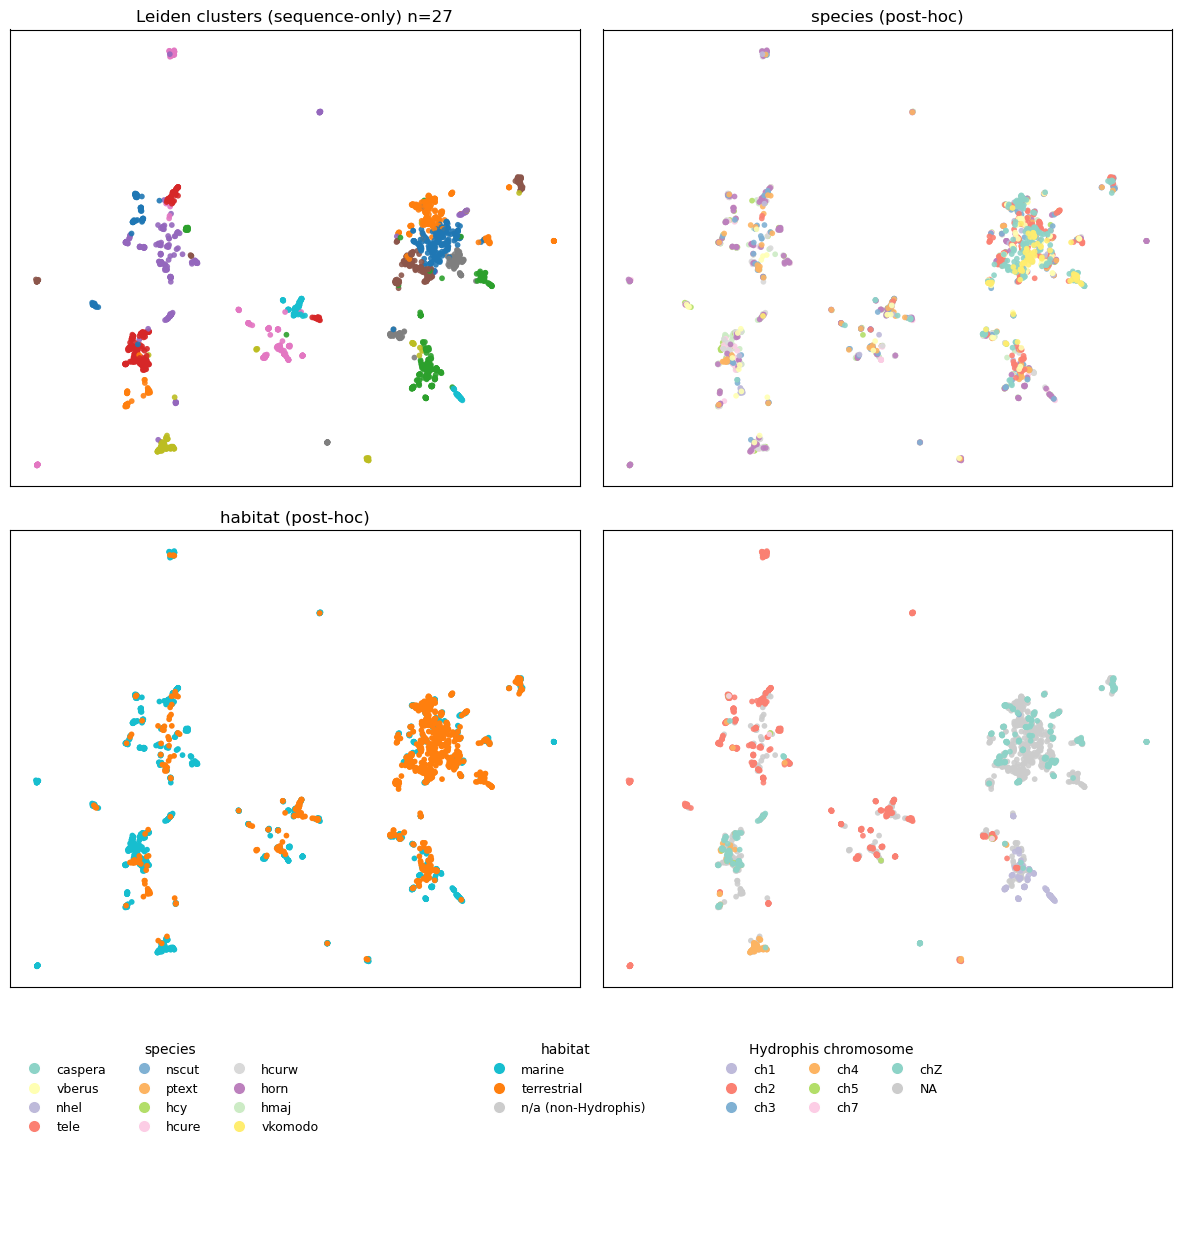

In [6]:
# Same four-panel UMAP. Cluster panel uses Leiden on the sequence PCA instead of HDBSCAN.

Xp = PCA(n_components=50, random_state=0).fit_transform(Xs)
knn = kneighbors_graph(Xp, n_neighbors=15, mode="connectivity", include_self=False)
src, dst = knn.nonzero()
g = ig.Graph(n=len(df), edges=list(zip(src.tolist(), dst.tolist())), directed=False)
g.simplify()
df["leiden"] = leidenalg.find_partition(
    g, leidenalg.RBConfigurationVertexPartition, resolution_parameter=1.0, seed=42
).membership
nleiden = int(df.leiden.nunique())

def roma(n):
    return [cmc.roma(x) for x in np.linspace(0, 1, max(n, 1))]

SPP = ["caspera","vberus","nhel","tele","nscut","ptext","hcy","hcure","hcurw","horn","hmaj","vkomodo"]
set2 = cm.get_cmap("tab10")
HAB_COL = {"marine": set2(9), "terrestrial": set2(1), "NA": "#cccccc"}
big = list(plt.get_cmap("tab10").colors)
clcol = lambda k: "#d9d9d9" if k == -1 else big[int(k) % len(big)]
chroms = sorted(c for c in df.chrom_hydrophis.fillna("NA").astype(str).unique() if c != "NA")
_set3 = plt.get_cmap("Set3").colors
chcol = {c: _set3[2:][i % len(_set3[2:])] for i, c in enumerate(chroms)}
chcol["NA"] = "#cccccc"
chcol["chZ"] = cm.get_cmap("Set3")(0)
chs = df.chrom_hydrophis.fillna("NA").astype(str)
na_mask = chs == "NA"
S, A = 17, 0.9
spcol = dict(zip(SPP, plt.get_cmap("Set3").colors[:len(SPP)]))

fig = plt.figure(figsize=(15, 15.5))
gs = GridSpec(3, 2, height_ratios=[1, 1, 0.42], hspace=0.12, wspace=0.04)
axTL, axTR = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
axBL, axBR = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
cap = fig.add_subplot(gs[2, :]); cap.axis("off")
for a in (axTL, axTR, axBL, axBR):
    a.set_xticks([]); a.set_yticks([])

axTL.scatter(df.umap1, df.umap2, c=[clcol(k) for k in df.leiden], s=S, alpha=A, lw=0)
axTL.set_title(f"Leiden clusters (sequence-only) n={nleiden}", fontsize=12)
axTR.scatter(df.umap1, df.umap2, c=[spcol.get(s, "#cccccc") for s in df.species], s=S, alpha=A, lw=0)
axTR.set_title("species (post-hoc)", fontsize=12)
hab = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")
axBL.scatter(df.umap1, df.umap2, c=[HAB_COL[h] for h in hab], s=S, alpha=1.0, lw=0)
axBL.set_title("habitat (post-hoc)", fontsize=12)
axBR.scatter(df.umap1[na_mask], df.umap2[na_mask], c=[chcol["NA"]] * int(na_mask.sum()), s=S, alpha=A, lw=0, zorder=1)
for chrom in chroms:
    mask = chs == chrom
    axBR.scatter(df.umap1[mask], df.umap2[mask], c=[chcol[chrom]] * int(mask.sum()), s=S, alpha=A, lw=0, zorder=2)

dot = lambda col: Line2D([0], [0], marker="o", color="w", markerfacecolor=col, markersize=9)
ck = chroms + ["NA"]
l1 = cap.legend([dot(spcol[s]) for s in SPP], SPP, title="species", loc="upper left",
                bbox_to_anchor=(0.0, 1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
l2 = cap.legend([dot(HAB_COL[k]) for k in ["marine", "terrestrial", "NA"]],
                ["marine", "terrestrial", "n/a (non-Hydrophis)"], title="habitat", loc="upper left",
                bbox_to_anchor=(0.40, 1.0), ncol=1, frameon=False, fontsize=9, title_fontsize=10)
cap.legend([dot(chcol[x]) for x in ck], ck, title="Hydrophis chromosome", loc="upper left",
           bbox_to_anchor=(0.60, 1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
cap.add_artist(l1); cap.add_artist(l2)
save_panels(fig, [(axTL, "cluster"), (axTR, "species"), (axBL, "habitat"), (axBR, "chromosome")], f"{OUT}/universe_umap_leiden")
plt.savefig(f"{OUT}/universe_umap_leiden.png", dpi=150, bbox_inches="tight"); plt.show()


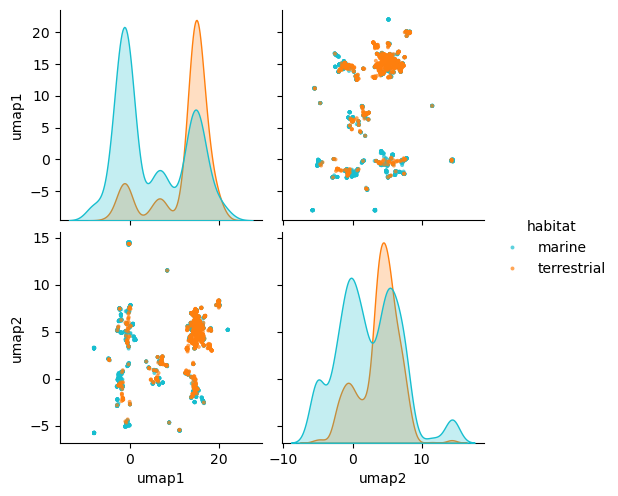

In [7]:
# Pair plot of the habitat UMAP
habitat = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")
umap_hab = df[["umap1", "umap2"]].assign(habitat=habitat)
sns.pairplot(umap_hab, hue="habitat", palette=HAB_COL, plot_kws={"s": 8, "alpha": 0.7, "linewidth": 0})

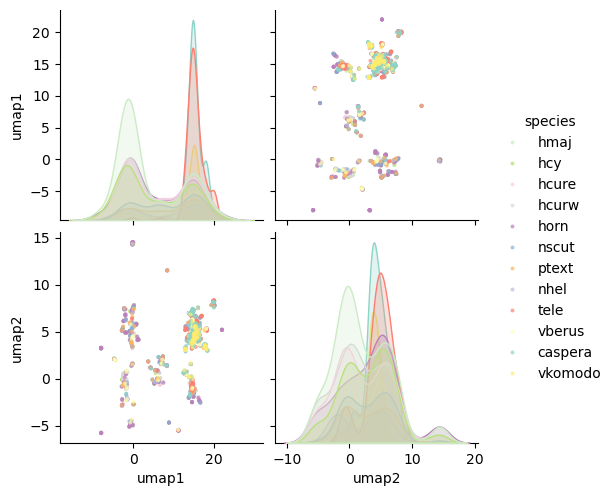

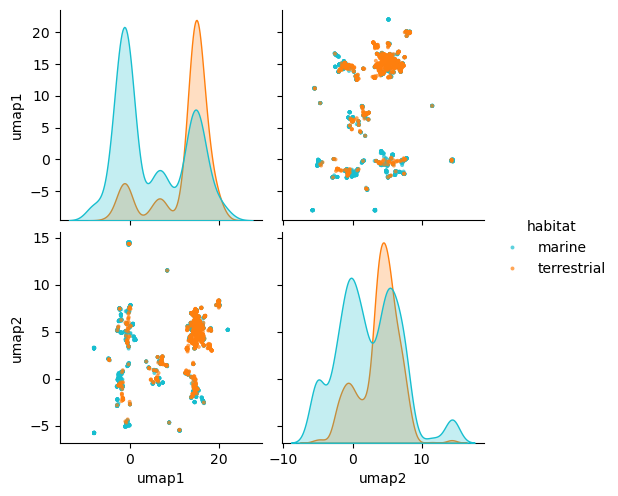

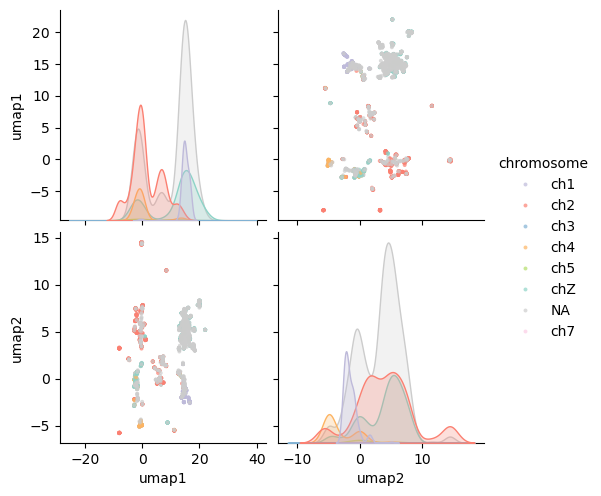

In [8]:
# Pair plots of the same 2D UMAP, one hue for each panel above.
plot = df[["umap1", "umap2"]].copy()
plot["species"] = df.species.fillna("NA")
plot["habitat"] = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")
plot["chromosome"] = df.chrom_hydrophis.fillna("NA").astype(str)
kw = dict(vars=["umap1", "umap2"], plot_kws={"s": 8, "alpha": 0.7, "linewidth": 0})


spp_pal = dict(spcol)
for s in plot.species.unique():
    spp_pal.setdefault(s, "#cccccc")
sns.pairplot(plot, hue="species", palette=spp_pal, **kw)

sns.pairplot(plot, hue="habitat", palette=HAB_COL, **kw)

sns.pairplot(plot, hue="chromosome", palette=chcol, **kw)


### t-SNE 
- focuses primarily on tight local neighbours

KMeans 15  GMM 15  Leiden 27


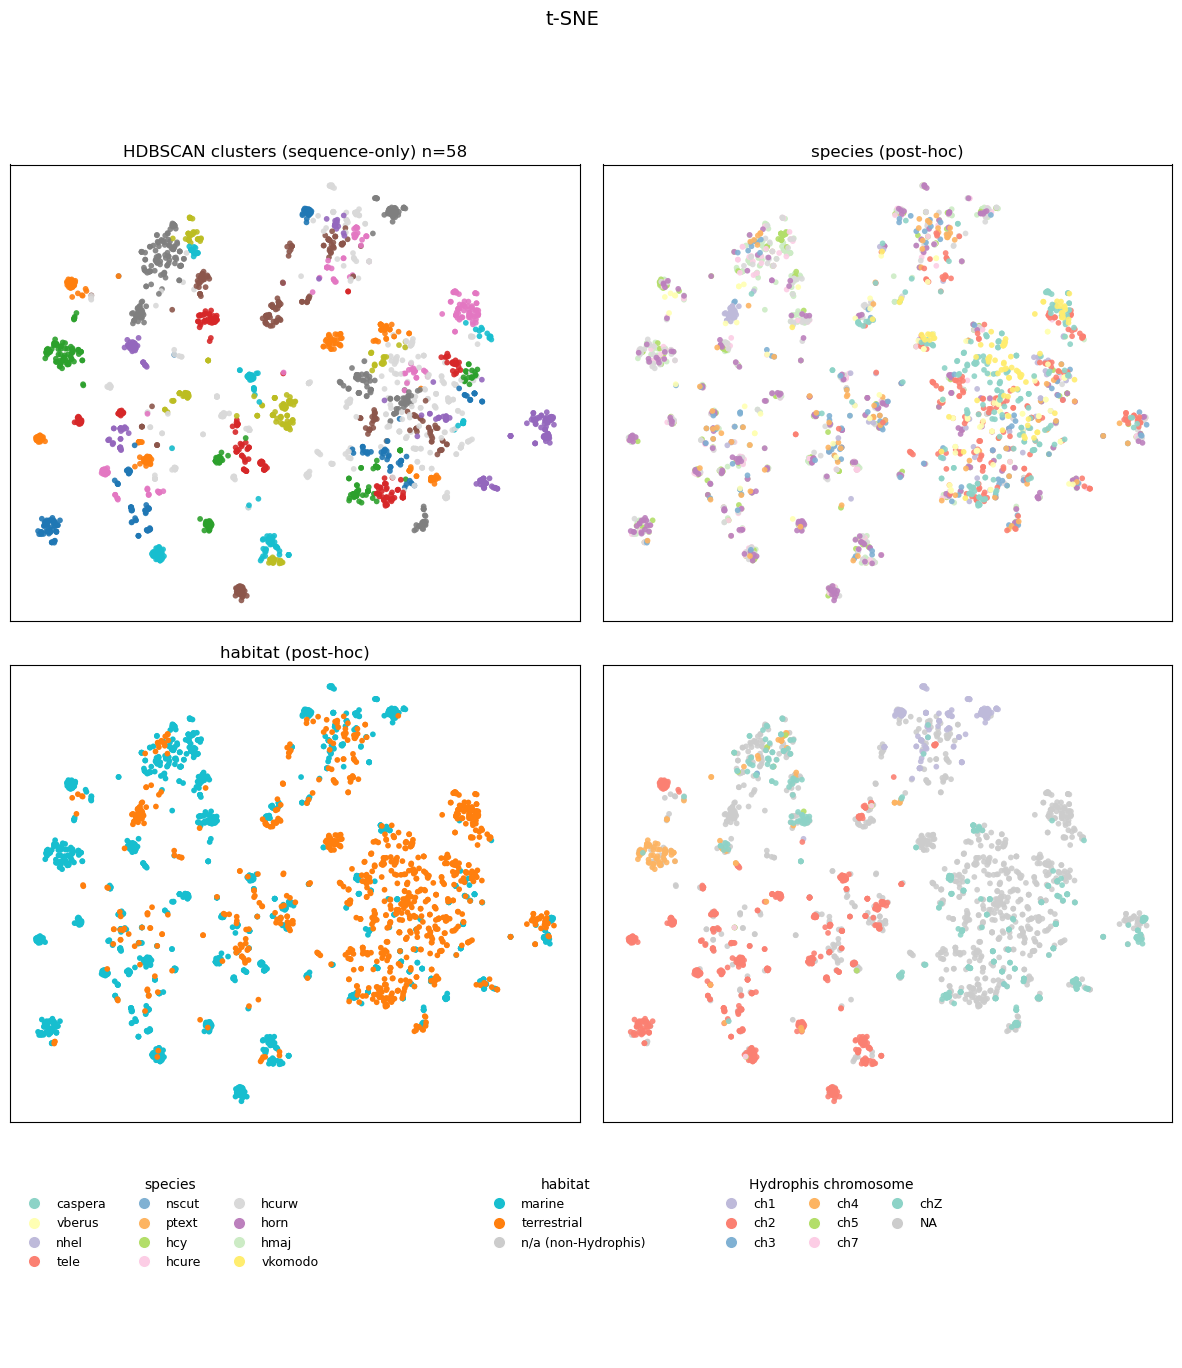

In [9]:
# t-SNE of the same standardised embeddings. Cluster on the sequence PCA, not on species or habitat.

Xp = PCA(n_components=50, random_state=0).fit_transform(Xs)
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(Xp)
df["tsne1"], df["tsne2"] = tsne[:, 0], tsne[:, 1]

# KMeans puts each gene in the nearest of k centres. The groups are similar in size.
# GMM fits k Gaussians and labels each gene by the component it most likely came from, so groups can be elongated and overlap.
# Leiden walks a k-nearest-neighbour graph and keeps the dense neighbourhoods. It does not take a fixed cluster count; resolution sets how finely it splits.
k = 15
df["kmeans"] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Xp)
df["gmm"] = GaussianMixture(n_components=k, covariance_type="diag", random_state=0).fit(Xp).predict(Xp)
knn = kneighbors_graph(Xp, n_neighbors=15, mode="connectivity", include_self=False)
src, dst = knn.nonzero()
g = ig.Graph(n=len(df), edges=list(zip(src.tolist(), dst.tolist())), directed=False)
g.simplify()
df["leiden"] = leidenalg.find_partition(
    g, leidenalg.RBConfigurationVertexPartition, resolution_parameter=1.0, seed=42
).membership
print(f"KMeans {df.kmeans.nunique()}  GMM {df.gmm.nunique()}  Leiden {df.leiden.nunique()}")

# Same four panels and the same colour maps as the UMAP figure. Cluster colours are the HDBSCAN labels.
chs = df.chrom_hydrophis.fillna("NA").astype(str)
na_mask = chs == "NA"
fig = plt.figure(figsize=(15, 15.5))
gs = GridSpec(3, 2, height_ratios=[1, 1, 0.42], hspace=0.12, wspace=0.04)
axTL, axTR = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
axBL, axBR = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
cap = fig.add_subplot(gs[2, :]); cap.axis("off")
for a in (axTL, axTR, axBL, axBR):
    a.set_xticks([]); a.set_yticks([])
axTL.scatter(df.tsne1, df.tsne2, c=[clcol(k) for k in df.cluster], s=S, alpha=A, lw=0)
axTL.set_title(f"HDBSCAN clusters (sequence-only) n={nclust}", fontsize=12)
axTR.scatter(df.tsne1, df.tsne2, c=[spcol.get(s, "#cccccc") for s in df.species], s=S, alpha=A, lw=0)
axTR.set_title("species (post-hoc)", fontsize=12)
hab = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")
axBL.scatter(df.tsne1, df.tsne2, c=[HAB_COL[h] for h in hab], s=S, alpha=1.0, lw=0)
axBL.set_title("habitat (post-hoc)", fontsize=12)
axBR.scatter(df.tsne1[na_mask], df.tsne2[na_mask], c=[chcol["NA"]] * int(na_mask.sum()), s=S, alpha=A, lw=0, zorder=1)
for chrom in chroms:
    mask = chs == chrom
    axBR.scatter(df.tsne1[mask], df.tsne2[mask], c=[chcol[chrom]] * int(mask.sum()), s=S, alpha=A, lw=0, zorder=2)
dot = lambda col: Line2D([0], [0], marker="o", color="w", markerfacecolor=col, markersize=9)
ck = chroms + ["NA"]
l1 = cap.legend([dot(spcol[s]) for s in SPP], SPP, title="species", loc="upper left",
                bbox_to_anchor=(0.0, 1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
l2 = cap.legend([dot(HAB_COL[k]) for k in ["marine", "terrestrial", "NA"]],
                ["marine", "terrestrial", "n/a (non-Hydrophis)"], title="habitat", loc="upper left",
                bbox_to_anchor=(0.40, 1.0), ncol=1, frameon=False, fontsize=9, title_fontsize=10)
cap.legend([dot(chcol[x]) for x in ck], ck, title="Hydrophis chromosome", loc="upper left",
           bbox_to_anchor=(0.60, 1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
cap.add_artist(l1); cap.add_artist(l2)
fig.suptitle("t-SNE", fontsize=14)
save_panels(fig, [(axTL, "cluster"), (axTR, "species"), (axBL, "habitat"), (axBR, "chromosome")], f"{OUT}/universe_tsne")
plt.savefig(f"{OUT}/universe_tsne.png", dpi=150, bbox_inches="tight")
plt.show()


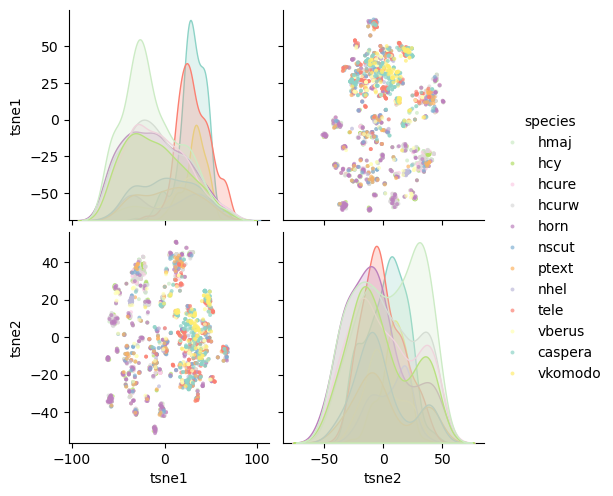

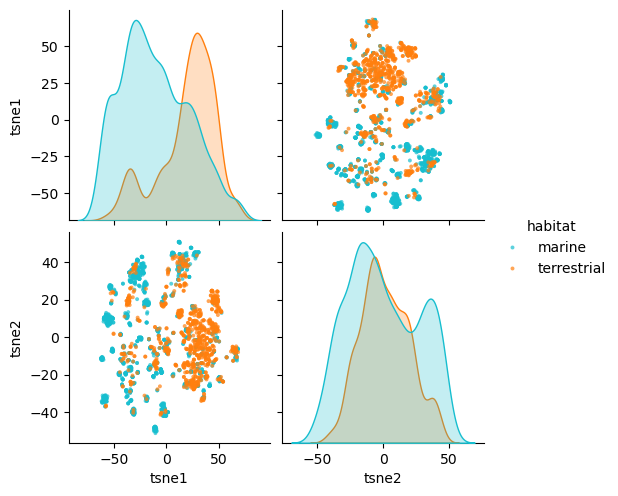

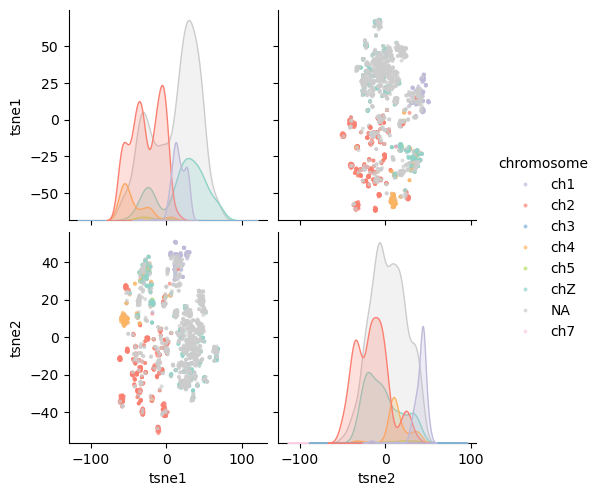

In [10]:
# Pair plots of the same 2D t-SNE, one hue for each panel above.
plot = df[["tsne1", "tsne2"]].copy()
plot["species"] = df.species.fillna("NA")
plot["habitat"] = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")
plot["chromosome"] = df.chrom_hydrophis.fillna("NA").astype(str)
kw = dict(vars=["tsne1", "tsne2"], plot_kws={"s": 8, "alpha": 0.7, "linewidth": 0})

spp_pal = dict(spcol)
for s in plot.species.unique():
    spp_pal.setdefault(s, "#cccccc")
sns.pairplot(plot, hue="species", palette=spp_pal, **kw)
sns.pairplot(plot, hue="habitat", palette=HAB_COL, **kw)
sns.pairplot(plot, hue="chromosome", palette=chcol, **kw)


chromosome labels mapped for 2016/2423 genes across 11 species


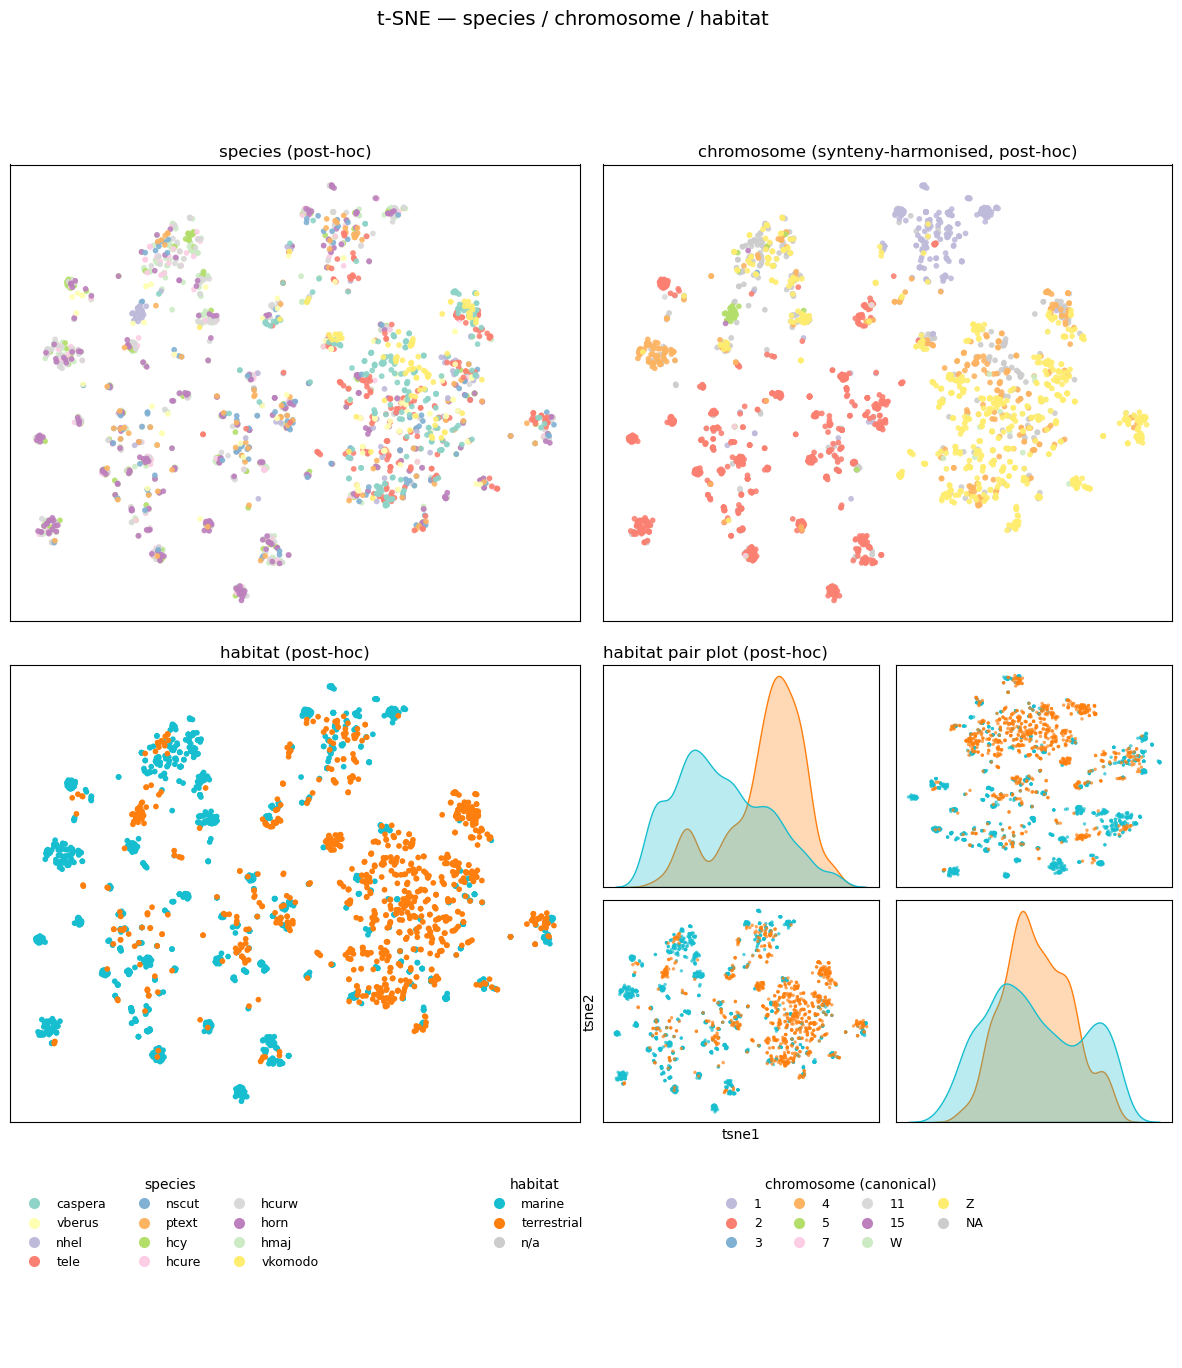

In [12]:
# t-SNE 2x2 facet: species / chromosome / habitat / habitat pair plot.
# Chromosome IDs are harmonised across all 12 genomes via the McScanX synteny
# correspondence table (native seqid -> canonical label 1..n, Z, W), NOT the
# Hydrophis-only chrom_hydrophis column. Colouring stays post-hoc (CLAUDE.md 2.1).
import csv
from matplotlib.gridspec import GridSpecFromSubplotSpec

SYN = "/hpcfs/users/a1864358/sanders_lab/asm/files/synteny/mcscan-synteny"
CORR = f"{SYN}/plot/chrom_correspondence.tsv"

# Palettes pinned to the UMAP-figure definitions (cell [9]): tab10 habitat, Set3 species.
# Pinned locally so this cell is correct even if the IsUMap cell (roma) has already run.
_hab = cm.get_cmap("tab10")
HAB_COL = {"marine": _hab(9), "terrestrial": _hab(1), "NA": "#cccccc"}
spcol = dict(zip(SPP, plt.get_cmap("Set3").colors[:len(SPP)]))

# (species, native_chrom) -> canonical chromosome label, from both A and B sides of each row.
nat2canon = {}
with open(CORR) as fh:
    for r in csv.DictReader(fh, delimiter="\t"):
        for g, n, l in [(r["genome_A"], r["chrA_native"], r["chrA_label"]),
                        (r["genome_B"], r["chrB_native"], r["chrB_label"])]:
            nat2canon.setdefault((g, n), l)

# df carries no seqid -> pull the native chromosome id from the covariate table and map it.
seqid = df.merge(cov[["gene", "seqid"]], on="gene", how="left")["seqid"].astype("string")
df["chrom_canon"] = [nat2canon.get((s, q), pd.NA) for s, q in zip(df.species, seqid)]
cc = df.chrom_canon.fillna("NA").astype(str)
mapped = cc.ne("NA")
print(f"chromosome labels mapped for {int(mapped.sum())}/{len(df)} genes "
      f"across {df.loc[mapped, 'species'].nunique()} species")

# Natural order: autosomes ascending, then sex chromosomes.
def _ckey(c):
    return (0, int(c)) if c.isdigit() else (1, c)
canon = sorted((c for c in cc.unique() if c != "NA"), key=_ckey)

# Chromosome palette (Set3-style, same family as the other t-SNE panels).
_pal = plt.get_cmap("Set3").colors[2:]
chcol_c = {c: _pal[i % len(_pal)] for i, c in enumerate(canon)}
chcol_c["NA"] = "#cccccc"

hab = df.marine.map({True: "marine", False: "terrestrial"}).fillna("NA")

fig = plt.figure(figsize=(15, 15.5))
gs = GridSpec(3, 2, height_ratios=[1, 1, 0.42], hspace=0.12, wspace=0.04)
axTL, axTR = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
axBL = fig.add_subplot(gs[1, 0])
cap = fig.add_subplot(gs[2, :]); cap.axis("off")
for a in (axTL, axTR, axBL):
    a.set_xticks([]); a.set_yticks([])

# Top-left: species (post-hoc).
axTL.scatter(df.tsne1, df.tsne2, c=[spcol.get(s, "#cccccc") for s in df.species], s=S, alpha=A, lw=0)
axTL.set_title("species (post-hoc)", fontsize=12)

# Top-right: chromosome (synteny-harmonised canonical label). NA (unplaced) drawn behind.
na_c = cc == "NA"
axTR.scatter(df.tsne1[na_c], df.tsne2[na_c], c=[chcol_c["NA"]] * int(na_c.sum()), s=S, alpha=A, lw=0, zorder=1)
for chrom in canon:
    m = cc == chrom
    axTR.scatter(df.tsne1[m], df.tsne2[m], c=[chcol_c[chrom]] * int(m.sum()), s=S, alpha=A, lw=0, zorder=2)
axTR.set_title("chromosome (synteny-harmonised, post-hoc)", fontsize=12)

# Bottom-left: habitat (post-hoc).
axBL.scatter(df.tsne1, df.tsne2, c=[HAB_COL[h] for h in hab], s=S, alpha=1.0, lw=0)
axBL.set_title("habitat (post-hoc)", fontsize=12)

# Bottom-right: habitat pair plot of the two t-SNE axes (seaborn-pairplot style, cell [10]):
# off-diagonal = scatter, diagonal = per-habitat KDE. Nested 2x2 inside the facet quadrant.
pvars = ["tsne1", "tsne2"]
inner = GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[1, 1], hspace=0.06, wspace=0.06)
pax = [[fig.add_subplot(inner[r, c]) for c in range(2)] for r in range(2)]
for r in range(2):
    for c in range(2):
        ax = pax[r][c]; ax.set_xticks([]); ax.set_yticks([])
        if r == c:   # diagonal: distribution of this axis, split by habitat
            for h in ["terrestrial", "marine"]:
                sns.kdeplot(x=df.loc[hab == h, pvars[r]], ax=ax, color=HAB_COL[h],
                            fill=True, alpha=0.3, lw=1, warn_singular=False)
            ax.set_ylabel("")
        else:        # off-diagonal: scatter coloured by habitat
            ax.scatter(df[pvars[c]], df[pvars[r]], c=[HAB_COL[h] for h in hab], s=6, alpha=0.7, lw=0)
# Edge labels, as seaborn pairplot does.
pax[1][0].set_xlabel("tsne1"); pax[1][1].set_xlabel("tsne2")
pax[0][0].set_ylabel("tsne1"); pax[1][0].set_ylabel("tsne2")
pax[0][0].set_title("habitat pair plot (post-hoc)", loc="left", fontsize=12)

# Legends on the bottom strip: species + habitat + canonical chromosome.
dot = lambda col: Line2D([0], [0], marker="o", color="w", markerfacecolor=col, markersize=9)
ck = canon + ["NA"]
l1 = cap.legend([dot(spcol[s]) for s in SPP], SPP, title="species", loc="upper left",
                bbox_to_anchor=(0.0, 1.0), ncol=3, frameon=False, fontsize=9, title_fontsize=10)
l2 = cap.legend([dot(HAB_COL[k]) for k in ["marine", "terrestrial", "NA"]],
                ["marine", "terrestrial", "n/a"], title="habitat", loc="upper left",
                bbox_to_anchor=(0.40, 1.0), ncol=1, frameon=False, fontsize=9, title_fontsize=10)
cap.legend([dot(chcol_c[x]) for x in ck], ck, title="chromosome (canonical)", loc="upper left",
           bbox_to_anchor=(0.60, 1.0), ncol=4, frameon=False, fontsize=9, title_fontsize=10)
cap.add_artist(l1); cap.add_artist(l2)

fig.suptitle("t-SNE — species / chromosome / habitat", fontsize=14)
# habitat_pair is a nested grid, not a single axis, so it is not saved as a standalone panel.
save_panels(fig, [(axTL, "species"), (axTR, "chromosome_canon"), (axBL, "habitat")],
            f"{OUT}/universe_tsne_habitat")
plt.savefig(f"{OUT}/universe_tsne_habitat.png", dpi=150, bbox_inches="tight")
plt.show()


#### Methods — post-hoc colouring

Clusters in the V2R sequence universe were defined from protein sequence alone: ESM2-650M mean-pooled embeddings of the VFT and 7TM domains were standardised, reduced (PCA/UMAP/t-SNE), and partitioned by density- and graph-based clustering (HDBSCAN, Leiden, KMeans, GMM) without reference to any organismal or genomic annotation. Species, habitat (marine vs. terrestrial), and chromosome of origin were then overlaid onto the fixed embedding *post hoc*, as colourings only, and never entered the distance computation or clustering. This design is deliberate: our central hypotheses — that sequence-defined V2R subtypes associate with particular chromosomes or with the marine transition — are testable only if those variables are excluded from cluster formation. Supplying habitat or chromosomal location as clustering input would make any subsequent "association" circular, recovering a structure that was imposed rather than discovered, and would further confound the signal because species, habitat, and chromosome are themselves correlated. By holding the clustering sequence-only, the overlays constitute an independent test of concordance, which we quantify as the agreement (adjusted Rand index and normalised mutual information) between the sequence clusters and each annotation rather than by visual inspection. Chromosome labels used in these overlays were harmonised across all twelve genomes through the McScanX synteny correspondence table, mapping each gene's native scaffold identifier to a canonical chromosome label so that homologous chromosomes are comparable across species.
